# Problem 4.6

Consider a slightly modified version of the function from Prob. 4.5, where we add a $x_2^4$ term to get

$$f = x_1^4 + x_2^4 + 3 x_1^3 + 3 x_2^2 - 6 x_1 x_2 - 2 x_2.$$

Can you find the critical points analytically? Plot the function contours. Locate the critical points graphically and classify them.

In [19]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Approach

In [20]:
def f(x):
    x1, x2 = x
    return x1 ** 4 + x2 ** 4 + 3 * x1 ** 3 + 3 * x2 ** 2 - 6 * x1 * x2 - 2 * x2

def contour(f, xlim, ylim, n=200, levels=40, ax=None):
    """Contour plot of a 2D function f(x) with x = [x1, x2]; returns the axes."""
    x1, x2 = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    z = np.vectorize(lambda a, b: f(np.array([a, b])))(x1, x2)
    if ax is None:
        _, ax = plt.subplots()
    ax.contour(x1, x2, z, levels=levels)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    return ax

# contour(f, (-3, 2), (-2, 3))

**calculate gradients**

$$\frac{\partial f}{\partial x_1} = 4 x_1^3 + 9 x_1^2 - 6 x_2 \qquad \text{(same as 4\_5)}$$

$$\frac{\partial f}{\partial x_2} = 4 x_2^3 + 6 x_2 - 6 x_1 - 2$$

**find critical points**

from $\dfrac{\partial f}{\partial x_2} = 0 = 4 x_2^3 + 6 x_2 - 6 x_1 - 2$ we get

$$x_1 = \frac{4 x_2^3 + 6 x_2 - 2}{6}$$

substitute into $\dfrac{\partial f}{\partial x_1} = 0$

$$0 = 4\left(\frac{4 x_2^3 + 6 x_2 - 2}{6}\right)^3 + 9\left(\frac{4 x_2^3 + 6 x_2 - 2}{6}\right)^2 - 6 x_2$$

simplify

$$0 = 4 \left(\frac{1}{6}\right)^3 (4 x_2^3 + 6 x_2 - 2)^3 + 9 \left(\frac{1}{6}\right)^2 (4 x_2^3 + 6 x_2 - 2)^2 - 6 x_2$$

$$x_2 = 4 \left(\frac{1}{6}\right)^4 (4 x_2^3 + 6 x_2 - 2)^3 + 9 \left(\frac{1}{6}\right)^3 (4 x_2^3 + 6 x_2 - 2)^2$$

$$x_2 = \frac{1}{324} (4 x_2^3 + 6 x_2 - 2)^3 + \frac{1}{24} (4 x_2^3 + 6 x_2 - 2)^2$$

$$324\, x_2 = (4 x_2^3 + 6 x_2 - 2)^3 + \frac{27}{2} (4 x_2^3 + 6 x_2 - 2)^2$$

$$\frac{81}{2}\, x_2 = (2 x_2^3 + 3 x_2 - 1)^3 + \frac{27}{4} (2 x_2^3 + 3 x_2 - 1)^2$$

...

this is getting complicated to do by hand. so doing it by hand is possible but not reasonable in this case. so i will continue with code

**calculate the hessian**

...

**classify the critical points**

...

In [21]:
# same method as problem 4_5

def grad_f(x):
    x1, x2 = x
    df_dx1 = 4 * x1 ** 3 + 9 * x1 ** 2 - 6 * x2
    df_dx2 = 4 * x2 ** 3 + 6 * x2 - 6 * x1 - 2
    return np.array([df_dx1, df_dx2])

def hess_f(x):
    x1, x2 = x
    d2f_dx1dx1 = 12 * x1 ** 2 + 18 * x1
    d2f_dx1dx2 = -6
    d2f_dx2dx1 = -6
    d2f_dx2dx2 = 12 * x2 ** 2 + 6
    return np.array([[d2f_dx1dx1, d2f_dx1dx2],
                     [d2f_dx2dx1, d2f_dx2dx2]])

x1_starts = np.linspace(-3, 2, 5)
x2_starts = np.linspace(-3, 2, 5)

critical_points = []
for x1_0 in x1_starts:
    for x2_0 in x2_starts:
        res = optimize.root(grad_f, [x1_0, x2_0], jac=hess_f)
        if not res.success:
            continue                                   # solver did not converge
        if any(np.allclose(res.x, cp, atol=1e-6) for cp in critical_points):
            continue                                   # already found
        critical_points.append(res.x)

critical_points = np.array(critical_points) #convert to array so we can sort it
critical_points = critical_points[np.argsort(critical_points[:, 0])] #sort by x1

for x in critical_points:
    eig = np.linalg.eigvalsh(hess_f(x))
    kind = "minimum" if np.all(eig > 0) else "maximum" if np.all(eig < 0) else "saddle"
    print(f"{np.round(x, 3)}  f = {f(x):.3f}  {kind}")

[-2.523 -1.157]  f = -17.053  minimum
[-0.25   0.083]  f = -0.064  saddle
[0.609 0.707]  f = -1.433  minimum


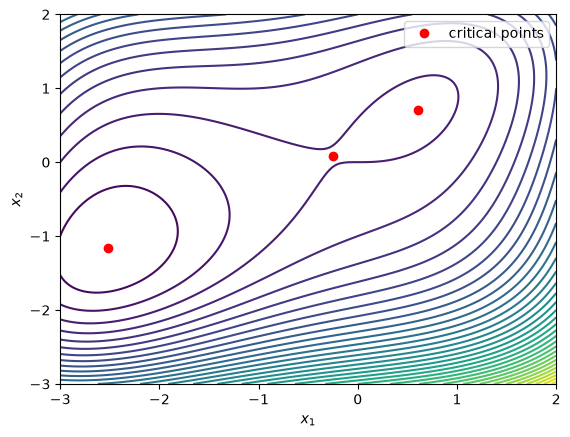

In [22]:
ax = contour(f, (-3, 2), (-3, 2))
ax.plot(critical_points[:, 0], critical_points[:, 1], 'ro', label="critical points")
ax.legend()

## Results

same amount of critical points as before, they are of the same type and they have similar values. the global minimum si now at x=[-2.523, -1.157], f(x)=-17.053. visualy the function is very similar to the one from 4_6

## Interpretation

this problem was significantly more difficult to solve by hand compared to before. but for the computer this was not the case. the main lesson is that a problem that is difficult to solve analyticaly can be quite easy to solve with code.